# Рекомендательная система фильмов

**Цель работы:** построить рекомендательную систему по фильмам

Система умеет:
1. показывать **топ-10 популярных фильмов**;
2. рекомендовать по **коллаборативной фильтрации** по пользователям и по фильмам;
3. подбирать **10 похожих фильмов по контенту**;
4. давать **персональные рекомендации** конкретному пользователю;
6. оценивать по метрикам **Precision@10 / Recall@10** и сравнивать с простым топом популярных.

**Данные:** MovieLens - 100 836 оценок, 610 пользователей, 9 742 фильма. Постеры - TMDB.

## 1. Импорт библиотек

In [74]:
%matplotlib inline
import matplotlib

In [75]:
import glob
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_colwidth", 60)
RANDOM_STATE = 42

## 2. Загрузка данных

Три таблицы:
- `movies.csv` — фильмы (id, название, год, жанры);
- `ratings.csv` — оценки пользователей (userId, movieId, rating, timestamp);
- `photo.csv` — ссылки на постеры (TMDB).

In [76]:
movies = pd.read_csv("movies.csv")
photo = pd.read_csv("photo.csv")

ratings_file = sorted(glob.glob("ratings.csv"))[0]
print("Файл оценок:", ratings_file)
ratings = pd.read_csv(ratings_file)

print("movies :", movies.shape)
print("ratings:", ratings.shape)
print("photo  :", photo.shape)

Файл оценок: ratings.csv
movies : (9742, 6)
ratings: (100836, 4)
photo  : (9742, 5)


In [77]:
movies.head()

,movieId,imdbId,tmdbId,title,year,genres
0,1,tt0114709,862.000,Toy Story (1995),1995.000,Adventure|Animation|Children|Comedy|Fantasy
1,2,tt0113497,8844.000,Jumanji (1995),1995.000,Adventure|Children|Fantasy
2,3,tt0113228,15602.000,Grumpier Old Men (1995),1995.000,Comedy|Romance
3,4,tt0114885,31357.000,Waiting to Exhale (1995),1995.000,Comedy|Drama|Romance
4,5,tt0113041,11862.000,Father of the Bride Part II (1995),1995.000,Comedy


In [78]:
ratings.head()

,userId,movieId,rating,timestamp
0,1,1,4.000,964982703
1,1,3,4.000,964981247
2,1,6,4.000,964982224
3,1,47,5.000,964983815
4,1,50,5.000,964982931


In [79]:
photo.head()

,movieId,imdbId,tmdbId,poster_url,overview
0,1,tt0114709,862.000,https://image.tmdb.org/t/p/w342/uXDfjJbdP4ijW5hWSBrPrlKp...,"Led by Woody, Andy's toys live happily in his room until..."
1,2,tt0113497,8844.000,https://image.tmdb.org/t/p/w342/bdHG5Mo83VPobeZZdlSz0Y7H...,When siblings Judy and Peter discover an enchanted board...
2,3,tt0113228,15602.000,https://image.tmdb.org/t/p/w342/1FSXpj5e8l4KH6nVFO5SPUer...,A family wedding reignites the ancient feud between next...
3,4,tt0114885,31357.000,https://image.tmdb.org/t/p/w342/4wjGMwPsdlvi025ZqR4rXnFD...,"Cheated on, mistreated and stepped on, the women are hol..."
4,5,tt0113041,11862.000,https://image.tmdb.org/t/p/w342/rj4LBtwQ0uGrpBnCELr716Qo...,Just when George Banks has recovered from his daughter's...


## 3. Объединение и обработка данных

In [80]:
movies.info()

<class 'pandas.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   movieId  9742 non-null   int64  
 1   imdbId   9742 non-null   str    
 2   tmdbId   9734 non-null   float64
 3   title    9742 non-null   str    
 4   year     9729 non-null   float64
 5   genres   9742 non-null   str    
dtypes: float64(2), int64(1), str(3)
memory usage: 940.0 KB


In [81]:
print("Пропусков в movies :", movies.isna().sum().to_dict())
print("Пропусков в ratings:", ratings.isna().sum().to_dict())
print("Дубликатов (userId, movieId):", ratings.duplicated(["userId", "movieId"]).sum())
print("Фильмов без жанров:", (movies.genres == "(no genres listed)").sum())

Пропусков в movies : {'movieId': 0, 'imdbId': 0, 'tmdbId': 8, 'title': 0, 'year': 13, 'genres': 0}
Пропусков в ratings: {'userId': 0, 'movieId': 0, 'rating': 0, 'timestamp': 0}
Дубликатов (userId, movieId): 0
Фильмов без жанров: 34


In [82]:
ratings = ratings.drop_duplicates(["userId", "movieId"])
movies["genres"] = movies["genres"].replace("(no genres listed)", "")
photo["poster_url"] = photo["poster_url"].fillna("")

df = (ratings
      .merge(movies, on="movieId")
      .merge(photo[["movieId", "poster_url"]], on="movieId", how="left"))
df["poster_url"] = df["poster_url"].fillna("")
df = df.drop(columns=["timestamp"])
df.head()

,userId,movieId,rating,imdbId,tmdbId,title,year,genres,poster_url
0,1,1,4.000,tt0114709,862.000,Toy Story (1995),1995.000,Adventure|Animation|Children|Comedy|Fantasy,https://image.tmdb.org/t/p/w342/uXDfjJbdP4ijW5hWSBrPrlKp...
1,1,3,4.000,tt0113228,15602.000,Grumpier Old Men (1995),1995.000,Comedy|Romance,https://image.tmdb.org/t/p/w342/1FSXpj5e8l4KH6nVFO5SPUer...
2,1,6,4.000,tt0113277,949.000,Heat (1995),1995.000,Action|Crime|Thriller,https://image.tmdb.org/t/p/w342/umSVjVdbVwtx5ryCA2QXL44D...
3,1,47,5.000,tt0114369,807.000,Seven (a.k.a. Se7en) (1995),1995.000,Mystery|Thriller,https://image.tmdb.org/t/p/w342/191nKfP0ehp3uIvWqgPbFmI4...
4,1,50,5.000,tt0114814,629.000,"Usual Suspects, The (1995)",1995.000,Crime|Mystery|Thriller,https://image.tmdb.org/t/p/w342/99X2SgyFunJFXGAYnDv3sb9p...


### Знакомство с данными

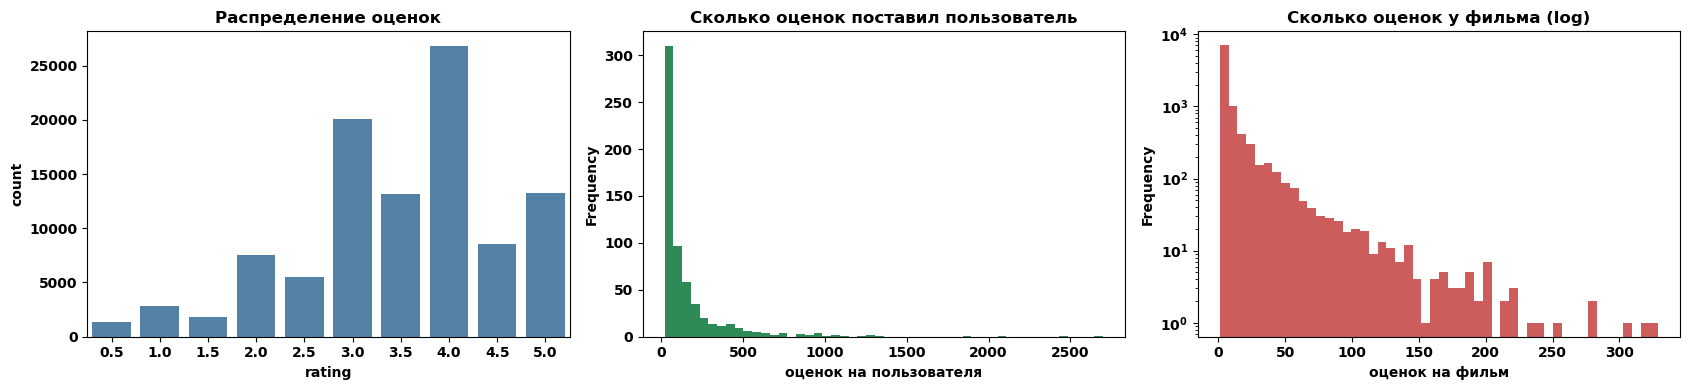

In [83]:
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

matplotlib.rcParams["font.family"] = "sans-serif"
matplotlib.rcParams["font.sans-serif"] = ["DejaVu Sans"]

fig, ax = plt.subplots(1, 3, figsize=(17, 4))

sns.countplot(x="rating", data=ratings, ax=ax[0], color="steelblue")
ax[0].set_title("Распределение оценок")

ratings.groupby("userId").size().plot.hist(bins=50, ax=ax[1], color="seagreen")
ax[1].set_title("Сколько оценок поставил пользователь")
ax[1].set_xlabel("оценок на пользователя")

ratings.groupby("movieId").size().plot.hist(bins=50, ax=ax[2], color="indianred", log=True)
ax[2].set_title("Сколько оценок у фильма (log)")
ax[2].set_xlabel("оценок на фильм")

plt.tight_layout()
plt.show()

In [84]:
sparsity = 1 - len(ratings) / (ratings.userId.nunique() * ratings.movieId.nunique())
print(f"Пользователей: {ratings.userId.nunique()},  фильмов с оценками: {ratings.movieId.nunique()}")
print(f"Разреженность матрицы «пользователь × фильм»: {sparsity:.2%}")

Пользователей: 610,  фильмов с оценками: 9724
Разреженность матрицы «пользователь × фильм»: 98.30%


Матрица оценок разрежена более чем на 98 %: каждый пользователь видел лишь малую часть фильмов.
Поэтому дальше используем разреженные матрицы (`csr_matrix`).

## 4. Рекомендации на основе популярности (взвешенный рейтинг)

Простой средний рейтинг несправедлив: фильм с одной оценкой «5.0» обгонит фильм с 1000 оценок «4.5».
Поэтому применяем формулу IMDb (Bayesian average):

$$WR = \frac{v}{v+m}\cdot R + \frac{m}{v+m}\cdot C$$

- $v$ — число оценок фильма; $R$ — средний рейтинг фильма;
- $m$ — «порог доверия» (90-й процентиль числа оценок);
- $C$ — средний рейтинг по всем фильмам.

In [85]:
movie_stats = (df.groupby("movieId")
                 .agg(avg_rating=("rating", "mean"), count_rating=("rating", "count"))
                 .reset_index())

v = movie_stats["count_rating"]
R = movie_stats["avg_rating"]
m = v.quantile(0.90)
C = R.mean()
movie_stats["w_score"] = (v * R + m * C) / (v + m)
print(f"m (порог доверия) = {m:.0f},  C (средний рейтинг) = {C:.3f}")

catalog = (movies.merge(photo[["movieId", "poster_url"]], on="movieId", how="left")
                 .merge(movie_stats, on="movieId", how="left"))
catalog["poster_url"] = catalog["poster_url"].fillna("")
catalog["count_rating"] = catalog["count_rating"].fillna(0).astype(int)
catalog = catalog.set_index("movieId", drop=False)

movie_stats.describe()

m (порог доверия) = 27,  C (средний рейтинг) = 3.262


,movieId,avg_rating,count_rating,w_score
count,9724.000,9724.000,9724.000,9724.000
mean,42245.024,3.262,10.370,3.283
std,52191.137,0.870,22.401,0.147
min,1.000,0.500,1.000,2.543
25%,3245.500,2.800,1.000,3.217
50%,7300.000,3.417,3.000,3.271
75%,76739.250,3.912,9.000,3.325
max,193609.000,5.000,329.000,4.337


In [86]:
def popular_movies(n=10, genre=None, min_votes=0):
    """Топ-N популярных фильмов по взвешенному рейтингу (можно по жанру)."""
    d = catalog[catalog.count_rating > min_votes]
    if genre:
        d = d[d.genres.str.split("|").apply(lambda g: genre in g)]
    cols = ["movieId", "title", "genres", "avg_rating", "count_rating", "w_score", "poster_url"]
    return d.sort_values("w_score", ascending=False).head(n)[cols].reset_index(drop=True)

top10 = popular_movies(10)
top10

,movieId,title,genres,avg_rating,count_rating,w_score,poster_url
0,318,"Shawshank Redemption, The (1994)",Crime|Drama,4.429,317,4.337,https://image.tmdb.org/t/p/w342/9cqNxx0GxF0bflZmeSMuL5tn...
1,858,"Godfather, The (1972)",Crime|Drama,4.289,192,4.162,https://image.tmdb.org/t/p/w342/3bhkrj58Vtu7enYsRolD1fZd...
2,2959,Fight Club (1999),Action|Crime|Drama|Thriller,4.273,218,4.162,https://image.tmdb.org/t/p/w342/jSziioSwPVrOy9Yow3XhWIBD...
3,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,4.231,251,4.137,https://image.tmdb.org/t/p/w342/fai0rspsNeJCS69wHNjOdWxc...
4,50,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,4.238,204,4.124,https://image.tmdb.org/t/p/w342/99X2SgyFunJFXGAYnDv3sb9p...
5,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,4.197,307,4.122,https://image.tmdb.org/t/p/w342/vQWk5YBFWF4bZaofAbv0tShw...
6,527,Schindler's List (1993),Drama|War,4.225,220,4.120,https://image.tmdb.org/t/p/w342/sF1U4EUQS8YHUYjNl3pMGNIQ...
7,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,4.192,278,4.110,https://image.tmdb.org/t/p/w342/dXNAPwY7VrqMAo51EKhhCJfa...
8,1196,Star Wars: Episode V - The Empire Strikes Back (1980),Action|Adventure|Sci-Fi,4.216,211,4.108,https://image.tmdb.org/t/p/w342/nNAeTmF4CtdSgMDplXTDPOpY...
9,356,Forrest Gump (1994),Comedy|Drama|Romance|War,4.164,329,4.096,https://image.tmdb.org/t/p/w342/saHP97rTPS5eLmrLQEcANmKr...


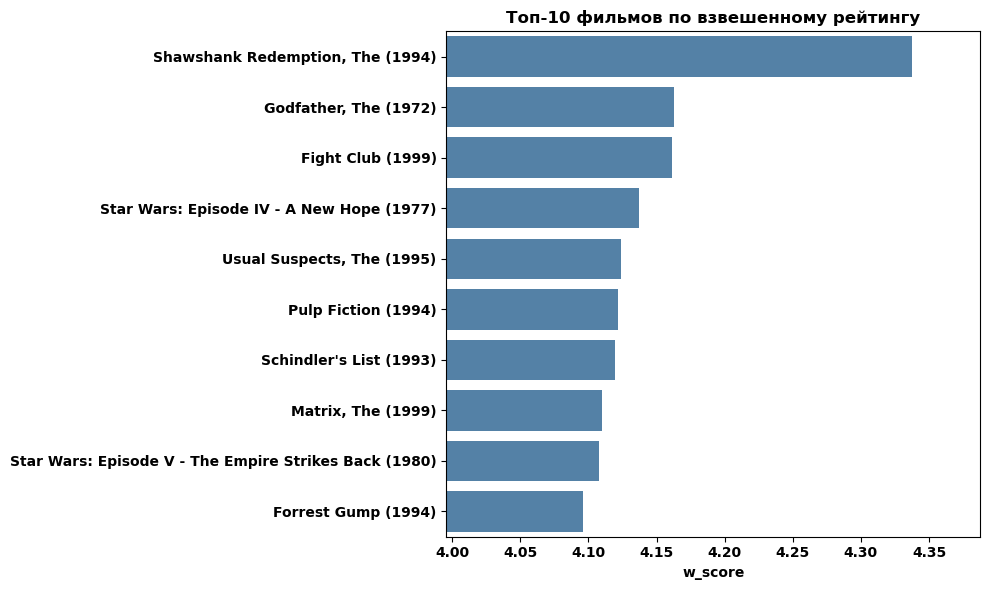

In [87]:
plt.figure(figsize=(10, 6))
sns.barplot(x="w_score", y="title", data=top10, color="steelblue")
plt.xlim(top10.w_score.min() - 0.1, top10.w_score.max() + 0.05)
plt.title("Топ-10 фильмов по взвешенному рейтингу")
plt.xlabel("w_score")
plt.ylabel("")
plt.tight_layout()
plt.show()

Топ по жанру:

In [88]:
popular_movies(10, genre="Comedy")

,movieId,title,genres,avg_rating,count_rating,w_score,poster_url
0,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,4.197,307,4.122,https://image.tmdb.org/t/p/w342/vQWk5YBFWF4bZaofAbv0tShw...
1,356,Forrest Gump (1994),Comedy|Drama|Romance|War,4.164,329,4.096,https://image.tmdb.org/t/p/w342/saHP97rTPS5eLmrLQEcANmKr...
2,1197,"Princess Bride, The (1987)",Action|Adventure|Comedy|Fantasy|Romance,4.232,142,4.077,https://image.tmdb.org/t/p/w342/2FC9L9MrjBoGHYjYZjdWQdop...
3,750,Dr. Strangelove or: How I Learned to Stop Worrying and L...,Comedy|War,4.268,97,4.049,https://image.tmdb.org/t/p/w342/gHm96BRW4GoI339rF1vYoYTB...
4,4973,"Amelie (Fabuleux destin d'Amélie Poulain, Le) (2001)",Comedy|Romance,4.183,120,4.014,https://image.tmdb.org/t/p/w342/nSxDa3M9aMvGVLoItzWTepQ5...
5,1136,Monty Python and the Holy Grail (1975),Adventure|Comedy|Fantasy,4.162,136,4.013,https://image.tmdb.org/t/p/w342/7nTkHjETdGMYK1phHwDbPsrz...
6,608,Fargo (1996),Comedy|Crime|Drama|Thriller,4.116,181,4.005,https://image.tmdb.org/t/p/w342/rt7cpEr1uP6RTZykBFhBTcRa...
7,4011,Snatch (2000),Comedy|Crime|Thriller,4.156,93,3.955,https://image.tmdb.org/t/p/w342/kJZoAHq1SLDdWjeNGtlHAnGp...
8,2324,Life Is Beautiful (La Vita è bella) (1997),Comedy|Drama|Romance|War,4.148,88,3.940,https://image.tmdb.org/t/p/w342/74hLDKjD5aGYOotO6esUVaeI...
9,1270,Back to the Future (1985),Adventure|Comedy|Sci-Fi,4.038,171,3.932,https://image.tmdb.org/t/p/w342/vN5B5WgYscRGcQpVhHl6p9DD...


In [89]:
popular_movies(10, genre="Sci-Fi")

,movieId,title,genres,avg_rating,count_rating,w_score,poster_url
0,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,4.231,251,4.137,https://image.tmdb.org/t/p/w342/fai0rspsNeJCS69wHNjOdWxc...
1,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,4.192,278,4.110,https://image.tmdb.org/t/p/w342/dXNAPwY7VrqMAo51EKhhCJfa...
2,1196,Star Wars: Episode V - The Empire Strikes Back (1980),Action|Adventure|Sci-Fi,4.216,211,4.108,https://image.tmdb.org/t/p/w342/nNAeTmF4CtdSgMDplXTDPOpY...
3,1210,Star Wars: Episode VI - Return of the Jedi (1983),Action|Adventure|Sci-Fi,4.138,196,4.032,https://image.tmdb.org/t/p/w342/jQYlydvHm3kUix1f8prMucrp...
4,7361,Eternal Sunshine of the Spotless Mind (2004),Drama|Romance|Sci-Fi,4.160,131,4.007,https://image.tmdb.org/t/p/w342/5MwkWH9tYHv3mV9OdYTMR5qr...
5,541,Blade Runner (1982),Action|Sci-Fi|Thriller,4.101,124,3.951,https://image.tmdb.org/t/p/w342/63N9uy8nd9j7Eog2axPQ8lbr...
6,79132,Inception (2010),Action|Crime|Drama|Mystery|Sci-Fi|Thriller|IMAX,4.066,143,3.939,https://image.tmdb.org/t/p/w342/xlaY2zyzMfkhk0HSC5VUwzoZ...
7,1270,Back to the Future (1985),Adventure|Comedy|Sci-Fi,4.038,171,3.932,https://image.tmdb.org/t/p/w342/vN5B5WgYscRGcQpVhHl6p9DD...
8,589,Terminator 2: Judgment Day (1991),Action|Sci-Fi,3.971,224,3.895,https://image.tmdb.org/t/p/w342/jFTVD4XoWQTcg7wdyJKa8PEd...
9,60069,WALL·E (2008),Adventure|Animation|Children|Romance|Sci-Fi,4.058,104,3.894,https://image.tmdb.org/t/p/w342/hbhFnRzzg6ZDmm8YAmxBnQpQ...


**Минус подхода:** всем пользователям показывается одно и то же. Для персонализации нужна коллаборативная фильтрация.

## 5. Матрица «пользователь x фильм»

Строки — пользователи, столбцы — фильмы (по `movieId`, т.к. названия у некоторых фильмов повторяются), значения — оценки (0 = не смотрел).

In [90]:
user_ids = np.sort(ratings.userId.unique())
movie_ids = np.sort(ratings.movieId.unique())
uidx = {u: i for i, u in enumerate(user_ids)}
midx = {mv: i for i, mv in enumerate(movie_ids)}

rows = ratings.userId.map(uidx).values
cols = ratings.movieId.map(midx).values
UI = csr_matrix((ratings.rating.values, (rows, cols)), shape=(len(user_ids), len(movie_ids)))
print("Матрица пользователь × фильм:", UI.shape, " ненулевых:", UI.nnz)

Матрица пользователь × фильм: (610, 9724)  ненулевых: 100836


### Вспомогательные функции: поиск фильма по названию и красивый вывод

In [91]:
def find_movie(query):
    """Находит movieId по части названия"""
    mask = catalog.title.str.contains(re.escape(query), case=False, na=False)
    found = catalog[mask].sort_values("count_rating", ascending=False)
    if found.empty:
        raise ValueError(f"Фильм «{query}» не найден")
    return int(found.iloc[0].movieId)


def show(movie_id_list, extra=None):
    """Таблица с описанием фильмов по списку movieId"""
    out = catalog.loc[movie_id_list, ["movieId", "title", "genres", "avg_rating", "count_rating", "w_score", "poster_url"]].copy()
    if extra is not None:
        for k, val in extra.items():
            out[k] = val
    return out.reset_index(drop=True)

## 6. Коллаборативная фильтрация по пользователям (user-based)

**Идея:** найти пользователей с похожим вкусом и порекомендовать то, что понравилось им, но чего целевой пользователь ещё не видел.

Сходство пользователей — **косинусное** между векторами их оценок. Для поиска соседей — `NearestNeighbors(metric='cosine')`.
Оценка фильма = взвешенная сумма оценок соседей (вес — сходство с пользователем), деленная на сумму весов тех соседей, кто фильм смотрел (+ сглаживание, чтобы фильмы с одной оценкой не лидировали).

In [92]:
knn_user = NearestNeighbors(metric="cosine", algorithm="brute")
knn_user.fit(UI)


def _scores_from_vector(vec, k=30, shrink=1.0):
    """Возвращает оценки-кандидаты для всех фильмов"""
    dist, ind = knn_user.kneighbors(vec, n_neighbors=k + 1)
    dist, ind = dist[0], ind[0]
    sim = 1 - dist
    # отбрасываем самого пользователя и нулевые сходства
    keep = (sim < 0.9999) & (sim > 0)
    sim, ind = sim[keep], ind[keep]
    neigh = UI[ind]
    num = neigh.T.dot(sim)                       
    den = (neigh > 0).T.astype(float).dot(sim) 
    return num / (den + shrink), den


def recommend_for_ratings(user_ratings, n=10, k=30, min_neighbors_weight=0.5, genres=None):
    """Рекомендации по произвольному словарю оценок"""
    vec = np.zeros(len(movie_ids))
    for mv, r in user_ratings.items():
        if mv in midx:
            vec[midx[mv]] = r
    scores, den = _scores_from_vector(csr_matrix(vec), k=k)
    scores = np.asarray(scores).ravel()
    den = np.asarray(den).ravel()
    scores[vec > 0] = -1                  
    scores[den < min_neighbors_weight] = -1    
    order = np.argsort(-scores)
    order = [i for i in order if scores[i] > 0]
    if genres:
        order = [i for i in order if genres in catalog.loc[movie_ids[i], "genres"]]
    order = order[:n]
    ids = [int(movie_ids[i]) for i in order]
    return show(ids, {"score": [scores[i] for i in order]})


def recommend_user_cf(user_id, n=10, k=30):
    """Рекомендации для пользователя из базы"""
    i = uidx[user_id]
    seen = {int(movie_ids[j]): UI[i, j] for j in UI[i].indices}
    return recommend_for_ratings(seen, n=n, k=k)

In [93]:
user = 1
print("Любимые фильмы пользователя", user)
fav = ratings[ratings.userId == user].sort_values("rating", ascending=False).head(10)
show(fav.movieId.tolist(), {"user_rating": fav.rating.tolist()})[["title", "genres", "user_rating"]]

Любимые фильмы пользователя 1


,title,genres,user_rating
0,Seven (a.k.a. Se7en) (1995),Mystery|Thriller,5.000
1,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,5.000
2,Bottle Rocket (1996),Adventure|Comedy|Crime|Romance,5.000
3,Dumb & Dumber (Dumb and Dumber) (1994),Adventure|Comedy,5.000
4,Billy Madison (1995),Comedy,5.000
5,Desperado (1995),Action|Romance|Western,5.000
6,Canadian Bacon (1995),Comedy|War,5.000
7,Rob Roy (1995),Action|Drama|Romance|War,5.000
8,Pinocchio (1940),Animation|Children|Fantasy|Musical,5.000
9,Tombstone (1993),Action|Drama|Western,5.000


In [94]:
print("Рекомендации user-based CF для пользователя", user)
recommend_user_cf(user)

Рекомендации user-based CF для пользователя 1


,movieId,title,genres,avg_rating,count_rating,w_score,poster_url,score
0,858,"Godfather, The (1972)",Crime|Drama,4.289,192,4.162,https://image.tmdb.org/t/p/w342/3bhkrj58Vtu7enYsRolD1fZd...,4.092
1,1221,"Godfather: Part II, The (1974)",Crime|Drama,4.260,129,4.087,https://image.tmdb.org/t/p/w342/8a1lJs7mFyGhGhZZDT1azJUo...,3.861
2,318,"Shawshank Redemption, The (1994)",Crime|Drama,4.429,317,4.337,https://image.tmdb.org/t/p/w342/9cqNxx0GxF0bflZmeSMuL5tn...,3.799
3,1387,Jaws (1975),Action|Horror,4.005,91,3.835,https://image.tmdb.org/t/p/w342/lxM6kqilAdpdhqUl2biYp5fr...,3.794
4,2762,"Sixth Sense, The (1999)",Drama|Horror|Mystery,3.894,179,3.811,https://image.tmdb.org/t/p/w342/vOyfUXNFSnaTk7Vk5AjpsKTU...,3.727
5,4993,"Lord of the Rings: The Fellowship of the Ring, The (2001)",Adventure|Fantasy,4.106,198,4.005,https://image.tmdb.org/t/p/w342/6oom5QYQ2yQTMJIbnvbkBL9c...,3.709
6,1200,Aliens (1986),Action|Adventure|Horror|Sci-Fi,3.964,126,3.840,https://image.tmdb.org/t/p/w342/r1x5JGpyqZU8PYhbs4UcrO1X...,3.708
7,541,Blade Runner (1982),Action|Sci-Fi|Thriller,4.101,124,3.951,https://image.tmdb.org/t/p/w342/63N9uy8nd9j7Eog2axPQ8lbr...,3.686
8,589,Terminator 2: Judgment Day (1991),Action|Sci-Fi,3.971,224,3.895,https://image.tmdb.org/t/p/w342/jFTVD4XoWQTcg7wdyJKa8PEd...,3.678
9,1653,Gattaca (1997),Drama|Sci-Fi|Thriller,3.953,86,3.788,https://image.tmdb.org/t/p/w342/eSKr5Fl1MEC7zpAXaLWBWSBj...,3.665


In [95]:
user = 123
print("Любимые фильмы пользователя", user)
fav = ratings[ratings.userId == user].sort_values("rating", ascending=False).head(10)
display(show(fav.movieId.tolist(), {"user_rating": fav.rating.tolist()})[["title", "genres", "user_rating"]])
print("Рекомендации:")
recommend_user_cf(user)

Любимые фильмы пользователя 123


,title,genres,user_rating
0,Seven (a.k.a. Se7en) (1995),Mystery|Thriller,4.500
1,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,4.500
2,American History X (1998),Crime|Drama,4.500
3,Memento (2000),Mystery|Thriller,4.500
4,Fight Club (1999),Action|Crime|Drama|Thriller,4.500
5,21 (2008),Crime|Drama|Romance|Thriller,4.500
6,Angels & Demons (2009),Crime|Drama|Mystery|Thriller,4.500
7,How to Train Your Dragon (2010),Adventure|Animation|Children|Fantasy|IMAX,4.500
8,"Hunt, The (Jagten) (2012)",Drama,4.500
9,Django Unchained (2012),Action|Drama|Western,4.500


Рекомендации:


,movieId,title,genres,avg_rating,count_rating,w_score,poster_url,score
0,356,Forrest Gump (1994),Comedy|Drama|Romance|War,4.164,329,4.096,https://image.tmdb.org/t/p/w342/saHP97rTPS5eLmrLQEcANmKr...,3.704
1,58559,"Dark Knight, The (2008)",Action|Crime|Drama|IMAX,4.238,149,4.089,https://image.tmdb.org/t/p/w342/qJ2tW6WMUDux911r6m7haRef...,3.697
2,858,"Godfather, The (1972)",Crime|Drama,4.289,192,4.162,https://image.tmdb.org/t/p/w342/3bhkrj58Vtu7enYsRolD1fZd...,3.601
3,48516,"Departed, The (2006)",Crime|Drama|Thriller,4.252,107,4.053,https://image.tmdb.org/t/p/w342/nT97ifVT2J1yMQmeq20Qblg6...,3.530
4,91529,"Dark Knight Rises, The (2012)",Action|Adventure|Crime|IMAX,3.993,76,3.802,https://image.tmdb.org/t/p/w342/hr0L2aueqlP2BYUblTTjmtn0...,3.503
5,527,Schindler's List (1993),Drama|War,4.225,220,4.120,https://image.tmdb.org/t/p/w342/sF1U4EUQS8YHUYjNl3pMGNIQ...,3.489
6,50,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,4.238,204,4.124,https://image.tmdb.org/t/p/w342/99X2SgyFunJFXGAYnDv3sb9p...,3.443
7,1198,Raiders of the Lost Ark (Indiana Jones and the Raiders o...,Action|Adventure,4.207,200,4.095,https://image.tmdb.org/t/p/w342/ceG9VzoRAVGwivFU403Wc3AH...,3.435
8,1193,One Flew Over the Cuckoo's Nest (1975),Drama,4.203,133,4.044,https://image.tmdb.org/t/p/w342/kjWsMh72V6d8KRLV4EOoSJLT...,3.405
9,2028,Saving Private Ryan (1998),Action|Drama|War,4.146,188,4.035,https://image.tmdb.org/t/p/w342/uqx37cS8cpHg8U35f9U5IBlr...,3.403


Рекомендации у двух пользователей отличаются — система персонализирована.

## 7. Коллаборативная фильтрация по фильмам (item-based)

**Идея:** два фильма похожи, если их оценивают одни и те же люди одинаково. Каждый фильм — вектор оценок пользователей.
Чтобы вектора были содержательными, берём фильмы минимум с 10 оценками.

In [96]:
MIN_ITEM_RATINGS = 10
cnt = np.asarray((UI > 0).sum(axis=0)).ravel()
item_cols = np.where(cnt >= MIN_ITEM_RATINGS)[0]
item_movie_ids = movie_ids[item_cols]
iidx = {int(mv): i for i, mv in enumerate(item_movie_ids)}

IU = UI[:, item_cols].T.tocsr() 
print(f"Фильмов в item-модели (≥{MIN_ITEM_RATINGS} оценок): {IU.shape[0]} из {len(movie_ids)}")

knn_item = NearestNeighbors(metric="cosine", algorithm="brute")
knn_item.fit(IU)


def similar_movies_cf(title_or_id, n=10):
    """10 фильмов, которые оценивают так же, как выбранный"""
    mid = title_or_id if isinstance(title_or_id, (int, np.integer)) else find_movie(title_or_id)
    if mid not in iidx:
        raise ValueError("У фильма слишком мало оценок для item-based модели")
    dist, ind = knn_item.kneighbors(IU[iidx[mid]], n_neighbors=n + 1)
    ids = [int(item_movie_ids[j]) for j in ind[0][1:]]
    print("Фильм:", catalog.loc[mid, "title"])
    return show(ids, {"similarity": 1 - dist[0][1:]})

Фильмов в item-модели (≥10 оценок): 2269 из 9724


In [97]:
similar_movies_cf("Toy Story (1995)")

Фильм: Toy Story (1995)


,movieId,title,genres,avg_rating,count_rating,w_score,poster_url,similarity
0,3114,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,3.861,97,3.731,https://image.tmdb.org/t/p/w342/4rbcp3ng8n1MKHjpeqW0L7Fn...,0.573
1,480,Jurassic Park (1993),Action|Adventure|Sci-Fi|Thriller,3.750,238,3.700,https://image.tmdb.org/t/p/w342/d9mtMGQDLANKieb9PbD3yK7x...,0.566
2,780,Independence Day (a.k.a. ID4) (1996),Action|Adventure|Sci-Fi|Thriller,3.446,202,3.424,https://image.tmdb.org/t/p/w342/p0BPQGSPoSa8Ml0DAf2mB2kC...,0.564
3,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,4.231,251,4.137,https://image.tmdb.org/t/p/w342/fai0rspsNeJCS69wHNjOdWxc...,0.557
4,356,Forrest Gump (1994),Comedy|Drama|Romance|War,4.164,329,4.096,https://image.tmdb.org/t/p/w342/saHP97rTPS5eLmrLQEcANmKr...,0.547
5,364,"Lion King, The (1994)",Adventure|Animation|Children|Drama|Musical|IMAX,3.942,172,3.850,https://image.tmdb.org/t/p/w342/sKCr78MXSLixwmZ8DyJLrpMs...,0.541
6,1210,Star Wars: Episode VI - Return of the Jedi (1983),Action|Adventure|Sci-Fi,4.138,196,4.032,https://image.tmdb.org/t/p/w342/jQYlydvHm3kUix1f8prMucrp...,0.541
7,648,Mission: Impossible (1996),Action|Adventure|Mystery|Thriller,3.537,162,3.498,https://image.tmdb.org/t/p/w342/l5uxY5m5OInWpcExIpKG6AR3...,0.539
8,1265,Groundhog Day (1993),Comedy|Fantasy|Romance,3.944,143,3.836,https://image.tmdb.org/t/p/w342/gCgt1WARPZaXnq523ySQEUKi...,0.534
9,1270,Back to the Future (1985),Adventure|Comedy|Sci-Fi,4.038,171,3.932,https://image.tmdb.org/t/p/w342/vN5B5WgYscRGcQpVhHl6p9DD...,0.530


In [98]:
similar_movies_cf("Forrest Gump")

Фильм: Forrest Gump (1994)


,movieId,title,genres,avg_rating,count_rating,w_score,poster_url,similarity
0,318,"Shawshank Redemption, The (1994)",Crime|Drama,4.429,317,4.337,https://image.tmdb.org/t/p/w342/9cqNxx0GxF0bflZmeSMuL5tn...,0.713
1,480,Jurassic Park (1993),Action|Adventure|Sci-Fi|Thriller,3.750,238,3.700,https://image.tmdb.org/t/p/w342/d9mtMGQDLANKieb9PbD3yK7x...,0.688
2,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,4.197,307,4.122,https://image.tmdb.org/t/p/w342/vQWk5YBFWF4bZaofAbv0tShw...,0.686
3,110,Braveheart (1995),Action|Drama|War,4.032,237,3.953,https://image.tmdb.org/t/p/w342/or1gBugydmjToAEq7OZY0oww...,0.643
4,593,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller,4.161,279,4.082,https://image.tmdb.org/t/p/w342/uS9m8OBk1A8eM9I042bx8XXp...,0.639
5,150,Apollo 13 (1995),Adventure|Drama|IMAX,3.846,201,3.777,https://image.tmdb.org/t/p/w342/tVeKscCm2fY1xDXZk8PgnZ87...,0.628
6,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,4.192,278,4.110,https://image.tmdb.org/t/p/w342/dXNAPwY7VrqMAo51EKhhCJfa...,0.610
7,500,Mrs. Doubtfire (1993),Comedy|Drama,3.389,144,3.369,https://image.tmdb.org/t/p/w342/ualFkVe5zYDphGuJv37byW2S...,0.608
8,527,Schindler's List (1993),Drama|War,4.225,220,4.120,https://image.tmdb.org/t/p/w342/sF1U4EUQS8YHUYjNl3pMGNIQ...,0.602
9,589,Terminator 2: Judgment Day (1991),Action|Sci-Fi,3.971,224,3.895,https://image.tmdb.org/t/p/w342/jFTVD4XoWQTcg7wdyJKa8PEd...,0.601


In [99]:
similar_movies_cf("Fight Club")

Фильм: Fight Club (1999)


,movieId,title,genres,avg_rating,count_rating,w_score,poster_url,similarity
0,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,4.192,278,4.110,https://image.tmdb.org/t/p/w342/dXNAPwY7VrqMAo51EKhhCJfa...,0.714
1,4226,Memento (2000),Mystery|Thriller,4.123,159,3.998,https://image.tmdb.org/t/p/w342/nzlv62aC0octS5AklAiWpXLX...,0.670
2,2329,American History X (1998),Crime|Drama,4.217,129,4.052,https://image.tmdb.org/t/p/w342/x2drgoXYZ8484lqyDj7L1CEV...,0.649
3,6874,Kill Bill: Vol. 1 (2003),Action|Crime|Thriller,3.962,131,3.842,https://image.tmdb.org/t/p/w342/v7TaX8kXMXs5yFFGR41guUDN...,0.640
4,4993,"Lord of the Rings: The Fellowship of the Ring, The (2001)",Adventure|Fantasy,4.106,198,4.005,https://image.tmdb.org/t/p/w342/6oom5QYQ2yQTMJIbnvbkBL9c...,0.636
5,2858,American Beauty (1999),Drama|Romance,4.056,204,3.964,https://image.tmdb.org/t/p/w342/wby9315QzVKdW9BonAefg8jG...,0.626
6,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,4.197,307,4.122,https://image.tmdb.org/t/p/w342/vQWk5YBFWF4bZaofAbv0tShw...,0.623
7,7153,"Lord of the Rings: The Return of the King, The (2003)",Action|Adventure|Drama|Fantasy,4.119,185,4.010,https://image.tmdb.org/t/p/w342/rCzpDGLbOoPwLjy3OAm5NUPO...,0.622
8,79132,Inception (2010),Action|Crime|Drama|Mystery|Sci-Fi|Thriller|IMAX,4.066,143,3.939,https://image.tmdb.org/t/p/w342/xlaY2zyzMfkhk0HSC5VUwzoZ...,0.615
9,7438,Kill Bill: Vol. 2 (2004),Action|Drama|Thriller,3.868,110,3.749,https://image.tmdb.org/t/p/w342/2yhg0mZQMhDyvUQ4rG1IZ4oI...,0.614


## 8. Рекомендации по контенту (content-based)

**Идея:** рекомендуем фильмы, похожие по описанию, — не нужны оценки других пользователей, поэтому работает и для новых фильмов («холодный старт»).

Признаки фильма: **жанры** и **десятилетие выхода**. Превращаем в TF-IDF-вектора (редкие жанры, например Film-Noir, весят больше частых, как Drama) и ищем ближайших соседей по косинусному сходству.

In [100]:
def decade_token(year):
    return f"decade{int(year) // 10 * 10}" if pd.notna(year) else ""

content_text = (catalog.genres.str.replace("-", "").str.replace("|", " ", regex=False).str.lower()
                + " " + catalog.year.apply(decade_token))
tfidf = TfidfVectorizer(token_pattern=r"[a-z0-9]+")
X_content = tfidf.fit_transform(content_text)
print("Матрица признаков:", X_content.shape, "| признаки:", list(tfidf.get_feature_names_out())[:12], "...")

knn_content = NearestNeighbors(metric="cosine", algorithm="brute").fit(X_content)
cat_pos = {int(mid): i for i, mid in enumerate(catalog.index)}

Матрица признаков: (9742, 31) | признаки: ['action', 'adventure', 'animation', 'children', 'comedy', 'crime', 'decade1900', 'decade1910', 'decade1920', 'decade1930', 'decade1940', 'decade1950'] ...


In [101]:
def similar_movies_content(title_or_id, n=10, pool=200, min_votes=20):
    """10 фильмов, похожих по контенту"""
    mid = title_or_id if isinstance(title_or_id, (int, np.integer)) else find_movie(title_or_id)
    dist, ind = knn_content.kneighbors(X_content[cat_pos[mid]], n_neighbors=pool)
    cand = catalog.iloc[ind[0]].copy()
    cand["similarity"] = (1 - dist[0]).round(3)
    cand = cand[(cand.movieId != mid) & (cand.count_rating >= min_votes)]
    cand = cand.sort_values(["similarity", "w_score"], ascending=False).head(n)
    print("Фильм:", catalog.loc[mid, "title"], "|", catalog.loc[mid, "genres"])
    return cand[["movieId", "title", "genres", "avg_rating", "count_rating", "w_score", "poster_url", "similarity"]].reset_index(drop=True)

In [102]:
similar_movies_content("Toy Story (1995)")

Фильм: Toy Story (1995) | Adventure|Animation|Children|Comedy|Fantasy


,movieId,title,genres,avg_rating,count_rating,w_score,poster_url,similarity
0,3114,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,3.861,97,3.731,https://image.tmdb.org/t/p/w342/4rbcp3ng8n1MKHjpeqW0L7Fn...,1.000
1,2294,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy,3.244,45,3.251,https://image.tmdb.org/t/p/w342/lWPjxbUMpAHFkJpZHHNWhQaR...,1.000
2,673,Space Jam (1996),Adventure|Animation|Children|Comedy|Fantasy|Sci-Fi,2.708,53,2.895,https://image.tmdb.org/t/p/w342/4RN5El3Pj2W4gpwgiAGLVfSJ...,0.919
3,4886,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,3.871,132,3.768,https://image.tmdb.org/t/p/w342/wFSpyMsp7H0ttERbxY7Trlv8...,0.905
4,4016,"Emperor's New Groove, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,3.716,37,3.525,https://image.tmdb.org/t/p/w342/wwbgkXQBEKtnyIJapk6gUgWk...,0.905
5,53121,Shrek the Third (2007),Adventure|Animation|Children|Comedy|Fantasy,3.024,21,3.158,https://image.tmdb.org/t/p/w342/n4SexGGQzI26E269tfpa80MZ...,0.905
6,2355,"Bug's Life, A (1998)",Adventure|Animation|Children|Comedy,3.516,92,3.459,https://image.tmdb.org/t/p/w342/Ah3J9OJVc2CNCuH2zMydXy9f...,0.889
7,134853,Inside Out (2015),Adventure|Animation|Children|Comedy|Drama|Fantasy,3.814,43,3.601,https://image.tmdb.org/t/p/w342/2H1TmgdfNtsKlU9jKdeNyYL5...,0.868
8,4306,Shrek (2001),Adventure|Animation|Children|Comedy|Fantasy|Romance,3.868,170,3.785,https://image.tmdb.org/t/p/w342/iB64vpL3dIObOtMZgX3RqdVd...,0.850
9,108932,The Lego Movie (2014),Action|Adventure|Animation|Children|Comedy|Fantasy,3.871,31,3.588,https://image.tmdb.org/t/p/w342/lbctonEnewCYZ4FYoTZhs8ci...,0.842


In [103]:
similar_movies_content("The Lego Movie")

Фильм: The Lego Movie (2014) | Action|Adventure|Animation|Children|Comedy|Fantasy


,movieId,title,genres,avg_rating,count_rating,w_score,poster_url,similarity
0,134853,Inside Out (2015),Adventure|Animation|Children|Comedy|Drama|Fantasy,3.814,43,3.601,https://image.tmdb.org/t/p/w342/2H1TmgdfNtsKlU9jKdeNyYL5...,0.921
1,152081,Zootopia (2016),Action|Adventure|Animation|Children|Comedy,3.891,32,3.603,https://image.tmdb.org/t/p/w342/hlK0e0wAQ3VLuJcsfIYPvb4J...,0.903
2,95167,Brave (2012),Action|Adventure|Animation|Children,3.467,30,3.370,https://image.tmdb.org/t/p/w342/1XAuDtMWpL0sYSFK0R6EZate...,0.871
3,4886,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,3.871,132,3.768,https://image.tmdb.org/t/p/w342/wFSpyMsp7H0ttERbxY7Trlv8...,0.851
4,4016,"Emperor's New Groove, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,3.716,37,3.525,https://image.tmdb.org/t/p/w342/wwbgkXQBEKtnyIJapk6gUgWk...,0.851
5,53121,Shrek the Third (2007),Adventure|Animation|Children|Comedy|Fantasy,3.024,21,3.158,https://image.tmdb.org/t/p/w342/n4SexGGQzI26E269tfpa80MZ...,0.851
6,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,3.921,215,3.847,https://image.tmdb.org/t/p/w342/uXDfjJbdP4ijW5hWSBrPrlKp...,0.842
7,3114,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,3.861,97,3.731,https://image.tmdb.org/t/p/w342/4rbcp3ng8n1MKHjpeqW0L7Fn...,0.842
8,2294,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy,3.244,45,3.251,https://image.tmdb.org/t/p/w342/lWPjxbUMpAHFkJpZHHNWhQaR...,0.842
9,8961,"Incredibles, The (2004)",Action|Adventure|Animation|Children|Comedy,3.836,125,3.734,https://image.tmdb.org/t/p/w342/2LqaLgk4Z226KkgPJuiOQ58w...,0.804


## 9. Персональные рекомендации (гибрид)

Объединяем два источника для конкретного пользователя:
- **user-based CF** — что нравится похожим людям;
- **профиль вкуса по контенту** — средний TF-IDF-вектор фильмов, которые пользователь оценил высоко (≥ 4), и косинусная близость к нему всех фильмов.

Итоговый балл = `α · CF + (1 − α) · контент` (оба нормируются в [0, 1]).
Для нового пользователя без истории показываем топ популярных.

In [104]:
def _norm(a):
    a = np.asarray(a, dtype=float)
    rng = a.max() - a.min()
    return (a - a.min()) / rng if rng > 0 else np.zeros_like(a)


def recommend_hybrid_for_ratings(user_ratings, n=10, alpha=0.7, k=30, min_votes=10):
    """Гибрид по словарю оценок {movieId: rating}. Для пустого словаря — топ популярных."""
    liked = [mv for mv, r in user_ratings.items() if r >= 4 and mv in cat_pos]
    if not user_ratings or not liked:
        return popular_movies(n)
    vec = np.zeros(len(movie_ids))
    for mv, r in user_ratings.items():
        if mv in midx:
            vec[midx[mv]] = r
    cf, den = _scores_from_vector(csr_matrix(vec), k=k)
    cf = pd.Series(np.asarray(cf).ravel(), index=movie_ids)

    profile = np.asarray(X_content[[cat_pos[mv] for mv in liked]].mean(axis=0))
    content = pd.Series(cosine_similarity(profile, X_content).ravel(), index=catalog.index)

    cand = catalog.index[(catalog.count_rating >= min_votes) & (~catalog.index.isin(user_ratings.keys()))]
    cf_c = cf.reindex(cand).fillna(0).values
    ct_c = content.reindex(cand).values
    score = alpha * _norm(cf_c) + (1 - alpha) * _norm(ct_c)
    top = np.argsort(-score)[:n]
    return show(cand[top].tolist(), {"score": score[top]})


def recommend_hybrid(user_id, n=10, alpha=0.7):
    i = uidx[user_id]
    seen = {int(movie_ids[j]): UI[i, j] for j in UI[i].indices}
    return recommend_hybrid_for_ratings(seen, n=n, alpha=alpha)

In [105]:
recommend_hybrid(1)

,movieId,title,genres,avg_rating,count_rating,w_score,poster_url,score
0,318,"Shawshank Redemption, The (1994)",Crime|Drama,4.429,317,4.337,https://image.tmdb.org/t/p/w342/9cqNxx0GxF0bflZmeSMuL5tn...,0.857
1,1610,"Hunt for Red October, The (1990)",Action|Adventure|Thriller,3.872,90,3.732,https://image.tmdb.org/t/p/w342/yVl7zidse4KiWtGMqHFtZCx4...,0.857
2,1527,"Fifth Element, The (1997)",Action|Adventure|Comedy|Sci-Fi,3.746,116,3.654,https://image.tmdb.org/t/p/w342/fPtlCO1yQtnoLHOwKtWz7db6...,0.853
3,589,Terminator 2: Judgment Day (1991),Action|Sci-Fi,3.971,224,3.895,https://image.tmdb.org/t/p/w342/jFTVD4XoWQTcg7wdyJKa8PEd...,0.848
4,1200,Aliens (1986),Action|Adventure|Horror|Sci-Fi,3.964,126,3.840,https://image.tmdb.org/t/p/w342/r1x5JGpyqZU8PYhbs4UcrO1X...,0.845
5,7153,"Lord of the Rings: The Return of the King, The (2003)",Action|Adventure|Drama|Fantasy,4.119,185,4.010,https://image.tmdb.org/t/p/w342/rCzpDGLbOoPwLjy3OAm5NUPO...,0.842
6,2683,Austin Powers: The Spy Who Shagged Me (1999),Action|Adventure|Comedy,3.198,121,3.210,https://image.tmdb.org/t/p/w342/jiF7UShERJFn5RtgfBK2lIJr...,0.841
7,778,Trainspotting (1996),Comedy|Crime|Drama,4.039,102,3.877,https://image.tmdb.org/t/p/w342/1jUC02qsqS2NxBMFarbIhcQt...,0.839
8,353,"Crow, The (1994)",Action|Crime|Fantasy|Thriller,3.609,64,3.506,https://image.tmdb.org/t/p/w342/rMMB3v6jYHjsvXRNJYESacoT...,0.832
9,1653,Gattaca (1997),Drama|Sci-Fi|Thriller,3.953,86,3.788,https://image.tmdb.org/t/p/w342/eSKr5Fl1MEC7zpAXaLWBWSBj...,0.832


In [106]:
recommend_hybrid(414)

,movieId,title,genres,avg_rating,count_rating,w_score,poster_url,score
0,7022,Battle Royale (Batoru rowaiaru) (2000),Action|Drama|Horror|Thriller,3.933,30,3.616,https://image.tmdb.org/t/p/w342/aLGKAQKgzWpJ6egyWzzC11jX...,0.881
1,2324,Life Is Beautiful (La Vita è bella) (1997),Comedy|Drama|Romance|War,4.148,88,3.940,https://image.tmdb.org/t/p/w342/74hLDKjD5aGYOotO6esUVaeI...,0.875
2,48385,Borat: Cultural Learnings of America for Make Benefit Gl...,Comedy,3.346,65,3.322,https://image.tmdb.org/t/p/w342/7g9kBHMN2KTr5KUf8aen187M...,0.814
3,2288,"Thing, The (1982)",Action|Horror|Sci-Fi|Thriller,3.933,45,3.682,https://image.tmdb.org/t/p/w342/tzGY49kseSE9QAKk47uuDGwn...,0.806
4,70,From Dusk Till Dawn (1996),Action|Comedy|Horror|Thriller,3.509,55,3.428,https://image.tmdb.org/t/p/w342/sV3kIAmvJ9tPz4Lq5fuf9LLM...,0.805
5,6879,Runaway Jury (2003),Drama|Thriller,3.441,17,3.332,https://image.tmdb.org/t/p/w342/hpBot7sqaskTdZS264c7hOhG...,0.803
6,5528,One Hour Photo (2002),Drama|Thriller,3.474,19,3.350,https://image.tmdb.org/t/p/w342/fuSIN3Nq6dmaA8LZSkASpQue...,0.792
7,64969,Yes Man (2008),Comedy,3.618,34,3.460,https://image.tmdb.org/t/p/w342/8Vk2nQF1kY34x53YnWd5zDaT...,0.788
8,1203,12 Angry Men (1957),Drama,4.149,57,3.864,https://image.tmdb.org/t/p/w342/zhG3vKWyDRaZYoaww1UVAi29...,0.788
9,57640,Hellboy II: The Golden Army (2008),Action|Adventure|Fantasy|Sci-Fi,3.806,18,3.480,https://image.tmdb.org/t/p/w342/zO0Wdrxnhx3KoJEvychSmnY3...,0.786


### Новый пользователь: рекомендации по нескольким оценкам
Именно так будет работать приложение: пользователь оценивает несколько фильмов — система сразу даёт рекомендации.

In [107]:
new_user = {
    find_movie("Matrix, The"): 5,
    find_movie("Inception"): 5,
    find_movie("Interstellar"): 4.5,
    find_movie("Titanic (1997)"): 2,
}
print("Оценки нового пользователя:")
display(show(list(new_user), {"user_rating": list(new_user.values())})[["title", "genres", "user_rating"]])
print("Рекомендации:")
recommend_hybrid_for_ratings(new_user)

Оценки нового пользователя:


,title,genres,user_rating
0,"Matrix, The (1999)",Action|Sci-Fi|Thriller,5.000
1,Inception (2010),Action|Crime|Drama|Mystery|Sci-Fi|Thriller|IMAX,5.000
2,Interstellar (2014),Sci-Fi|IMAX,4.500
3,Titanic (1997),Drama|Romance,2.000


Рекомендации:


,movieId,title,genres,avg_rating,count_rating,w_score,poster_url,score
0,58559,"Dark Knight, The (2008)",Action|Crime|Drama|IMAX,4.238,149,4.089,https://image.tmdb.org/t/p/w342/qJ2tW6WMUDux911r6m7haRef...,0.887
1,2959,Fight Club (1999),Action|Crime|Drama|Thriller,4.273,218,4.162,https://image.tmdb.org/t/p/w342/jSziioSwPVrOy9Yow3XhWIBD...,0.850
2,89745,"Avengers, The (2012)",Action|Adventure|Sci-Fi|IMAX,3.870,69,3.699,https://image.tmdb.org/t/p/w342/RYMX2wcKCBAr24UyPD7xwmja...,0.801
3,91529,"Dark Knight Rises, The (2012)",Action|Adventure|Crime|IMAX,3.993,76,3.802,https://image.tmdb.org/t/p/w342/hr0L2aueqlP2BYUblTTjmtn0...,0.782
4,318,"Shawshank Redemption, The (1994)",Crime|Drama,4.429,317,4.337,https://image.tmdb.org/t/p/w342/9cqNxx0GxF0bflZmeSMuL5tn...,0.773
5,59315,Iron Man (2008),Action|Adventure|Sci-Fi,3.824,94,3.699,https://image.tmdb.org/t/p/w342/78lPtwv72eTNqFW9COBYI0dW...,0.744
6,44191,V for Vendetta (2006),Action|Sci-Fi|Thriller|IMAX,3.885,100,3.753,https://image.tmdb.org/t/p/w342/1avD1JeaRiJX5M4ahPdZPypG...,0.732
7,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,4.231,251,4.137,https://image.tmdb.org/t/p/w342/fai0rspsNeJCS69wHNjOdWxc...,0.721
8,7153,"Lord of the Rings: The Return of the King, The (2003)",Action|Adventure|Drama|Fantasy,4.119,185,4.010,https://image.tmdb.org/t/p/w342/rCzpDGLbOoPwLjy3OAm5NUPO...,0.718
9,2028,Saving Private Ryan (1998),Action|Drama|War,4.146,188,4.035,https://image.tmdb.org/t/p/w342/uqx37cS8cpHg8U35f9U5IBlr...,0.705


## 10. Оценка качества

Проверяем модели на отложенных данных:
1. Для каждого пользователя прячем 20 % его **хороших** оценок (≥ 4) — это «тест». Остальное — «обучение».
2. Модель строит топ-10 по обучающей части (уже оценённые фильмы исключаются).
3. Считаем **Precision@10** (доля попаданий в топ-10) и **Recall@10** (какую долю спрятанных фильмов нашли).

Сравниваем с базовым уровнем — «всем одно и то же, топ популярных».

In [108]:
rng = np.random.RandomState(RANDOM_STATE)
good = ratings[ratings.rating >= 4]
test_idx = (good.groupby("userId", group_keys=False)
                .apply(lambda g: g.sample(frac=0.2, random_state=RANDOM_STATE) if len(g) >= 5 else g.iloc[0:0]).index)
test = ratings.loc[test_idx]
train = ratings.drop(test_idx)
print(f"Обучение: {len(train)}, тест: {len(test)}, пользователей в тесте: {test.userId.nunique()}")

# матрицы по train
UI_tr = csr_matrix((train.rating.values, (train.userId.map(uidx).values, train.movieId.map(midx).values)),
                   shape=UI.shape)
test_sets = test.groupby("userId").movieId.apply(set).to_dict()

# кандидаты: фильмы с >= 20 оценками в train
cnt_tr = np.asarray((UI_tr > 0).sum(axis=0)).ravel()
cand_mask = cnt_tr >= 20
print("Фильмов-кандидатов:", cand_mask.sum())

Обучение: 91132, тест: 9704, пользователей в тесте: 603
Фильмов-кандидатов: 1198


In [109]:
def evaluate(score_fn, name, k=10):
    """вектор оценок по всем фильмам."""
    P, Rc = [], []
    for u, tset in test_sets.items():
        i = uidx[u]
        s = np.asarray(score_fn(i), dtype=float).ravel().copy()
        s[UI_tr[i].indices] = -np.inf 
        s[~cand_mask] = -np.inf
        top = np.argpartition(-s, k)[:k]
        top_ids = set(movie_ids[top])
        hits = len(top_ids & tset)
        P.append(hits / k)
        Rc.append(hits / len(tset))
    return {"model": name, f"Precision@{k}": np.mean(P), f"Recall@{k}": np.mean(Rc)}

# 1) популярность
st = pd.DataFrame({"v": cnt_tr, "R": np.asarray(UI_tr.sum(axis=0)).ravel() / np.maximum(cnt_tr, 1)})
m_tr, C_tr = st.v.quantile(0.9), st.R[st.v > 0].mean()
pop_score = ((st.v * st.R + m_tr * C_tr) / (st.v + m_tr)).values
res = [evaluate(lambda i: pop_score, "Популярные (baseline)")]

# 2) user-based CF
S_user = cosine_similarity(UI_tr)
np.fill_diagonal(S_user, 0)
def user_cf_scores(i, k=30):
    s = S_user[i]
    nn = np.argpartition(-s, k)[:k]
    w = s[nn]
    neigh = UI_tr[nn]
    num = neigh.T.dot(w)
    den = (neigh > 0).T.astype(float).dot(w)
    return num / (den + 1.0)
res.append(evaluate(user_cf_scores, "User-based CF"))

# 3) item-based CF
cols_c = np.where(cand_mask)[0]
IU_tr = UI_tr[:, cols_c].T.tocsr()
S_item = cosine_similarity(IU_tr)
np.fill_diagonal(S_item, 0)
def item_cf_scores(i):
    liked = UI_tr[i, :][:, cols_c].toarray().ravel()
    liked = np.where(liked >= 4, liked, 0)
    sc = np.full(UI.shape[1], -np.inf)
    sc[cols_c] = S_item.dot(liked)
    return sc
res.append(evaluate(item_cf_scores, "Item-based CF"))

results = pd.DataFrame(res).set_index("model")
results

,Precision@10,Recall@10
model,,
Популярные (baseline),0.117,0.100
User-based CF,0.197,0.191
Item-based CF,0.177,0.170


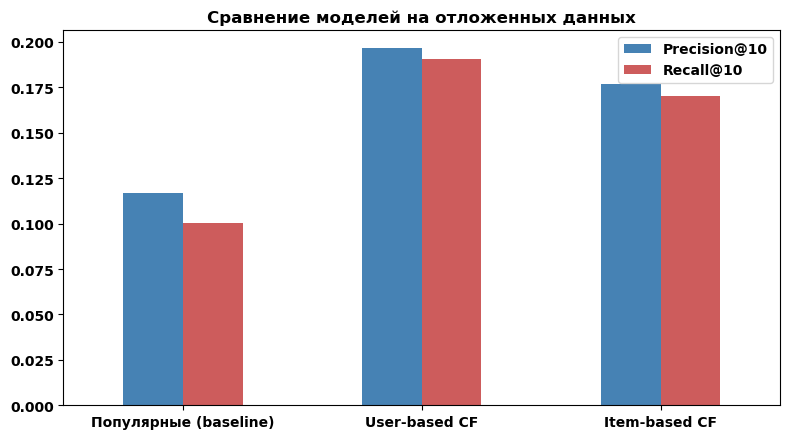

In [110]:
ax = results.plot.bar(figsize=(8, 4.5), rot=0, color=["steelblue", "indianred"])
ax.set_title("Сравнение моделей на отложенных данных")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

## 11. Выводы

- **Популярность** — быстрая, не требует истории пользователя, но не персонализирована; служит базовым уровнем и решением для новых пользователей.
- **User-based CF** — учитывает вкус конкретного человека; чувствительна к разреженности, требует хотя бы нескольких оценок.
- **Item-based CF** — стабильнее, «похожие фильмы» можно считать заранее; хорошо подходит для блока «Похожие фильмы».
- **Content-based** — не зависит от оценок, решает холодный старт для новых фильмов, но рекомендует «в той же коробке» (жанры).
- **Гибрид** сочетает CF и контент и работает для нового пользователя после нескольких оценок.

Эти функции (`popular_movies`, `recommend_user_cf`, `similar_movies_cf`, `similar_movies_content`, `recommend_hybrid`, `recommend_for_ratings`)
дальше переносятся в API (FastAPI) как отдельные эндпоинты, а приложение получает по ним списки рекомендаций.